In [1]:
%matplotlib inline
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'notebooks').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Run this notebook from inside the repository.')
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS = PROJECT_ROOT / 'notebooks/results/all4_coverage_1000/all4_one_each_retry_v5_validation30'
LINEAR = RESULTS / 'auxiliary_linear_fit'
INTERPRETATION = PROJECT_ROOT / 'notebooks/results/all4_coverage_1000/notebook01_training_temperature'
required = [
    RESULTS / 'recipe.json', RESULTS / 'completed.json', RESULTS / 'exposure.csv',
    RESULTS / 'test/latents.csv', RESULTS / 'test/per_network.csv', RESULTS / 'test/per_step.csv',
    LINEAR / 'per_network.csv', LINEAR / 'summary.csv', LINEAR / 'completed.json',
    INTERPRETATION / 'training_trajectory_markers.csv',
    INTERPRETATION / 'mixed_temperature_fluctuation.csv',
    INTERPRETATION / 'mixed_temperature_fluctuation_summary.csv',
    INTERPRETATION / 'metadata.json',
]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError('Missing required frozen artifacts:\n' + '\n'.join(missing))

recipe = json.loads((RESULTS / 'recipe.json').read_text())
completed = json.loads((RESULTS / 'completed.json').read_text())
linear_completed = json.loads((LINEAR / 'completed.json').read_text())
exposure = pd.read_csv(RESULTS / 'exposure.csv')
frame_df = pd.read_csv(RESULTS / 'test/latents.csv')
per_network = pd.read_csv(RESULTS / 'test/per_network.csv')
per_step = pd.read_csv(RESULTS / 'test/per_step.csv')
linear_network = pd.read_csv(LINEAR / 'per_network.csv')
linear_summary = pd.read_csv(LINEAR / 'summary.csv')
training_markers = pd.read_csv(INTERPRETATION / 'training_trajectory_markers.csv')
temperature_fluctuation = pd.read_csv(INTERPRETATION / 'mixed_temperature_fluctuation.csv')
temperature_fluctuation_summary = pd.read_csv(INTERPRETATION / 'mixed_temperature_fluctuation_summary.csv')

SOURCES = ['node_low', 'node_mixed', 'stiffness_low', 'stiffness_mixed']
MIXED_SOURCES = ['node_mixed', 'stiffness_mixed']
LOW_SOURCES = ['node_low', 'stiffness_low']
SOURCE_LABELS = {
    'node_low': 'node optimized · low-T',
    'node_mixed': 'node optimized · mixed-T',
    'stiffness_low': 'stiffness optimized · low-T',
    'stiffness_mixed': 'stiffness optimized · mixed-T',
}
SOURCE_COLORS = {
    'node_low': '#2166ac', 'node_mixed': '#67a9cf',
    'stiffness_low': '#b2182b', 'stiffness_mixed': '#ef8a62',
}
MODE_LABELS = {'ae_reconstruction': 'AE reconstruction', 'autonomous_delta_mlp': 'autonomous rollout'}
PAPER_WIDE_FIGSIZE = (11.4, 5.4)

plt.rcParams.update({
    'figure.dpi': 115, 'savefig.dpi': 160, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18,
    'axes.titleweight': 'semibold', 'font.size': 9.5, 'legend.frameon': False,
})

assert completed['status'] == 'completed' and linear_completed['status'] == 'completed'
assert recipe['config']['ae_config']['latent_dim'] == 2
assert set(frame_df.source.unique()) == set(SOURCES)
assert set(frame_df.trajectory_id.unique()) == set(range(40, 120))
assert frame_df.groupby(['source', 'trajectory_id']).size().eq(200).all()
print('Loaded one frozen 2D model and 320 held-out trajectories (80 per source × 200 stored frames).')


Loaded one frozen 2D model and 320 held-out trajectories (80 per source × 200 stored frames).


## Training data

Low/mixed pairs with the same ID share the underlying network identity. Therefore four training trajectories correspond to **two unique network structures**, observed once at each temperature profile. This is deliberately an extreme low-data representation experiment, not a claim about temperature-distribution coverage.


In [2]:
train_exposure = exposure.query("split == 'train'").copy()
train_exposure['dataset'] = train_exposure.source.map(SOURCE_LABELS)
train_exposure['temperature (K)'] = train_exposure.temperature
train_exposure['stored MD range'] = train_exposure.apply(
    lambda row: f"{int(row.first_time):,}–{int(row.last_time):,}", axis=1
)
display(train_exposure[['dataset', 'trajectory_id', 'temperature (K)', 'frames', 'stored MD range']].reset_index(drop=True))
print('Training total: 4 trajectories, 800 frames, 2 unique structures. Validation: 30 trajectories / 15 paired structures. Held-out development evaluation: IDs 40–119, never used for selection.')


,dataset,trajectory_id,temperature (K),frames,stored MD range
0,node optimized · low-T,0,1.000000e-07,200,"0–199,000"
1,node optimized · mixed-T,0,1.000000e-01,200,"0–199,000"
2,stiffness optimized · low-T,0,1.000000e-07,200,"0–199,000"
3,stiffness optimized · mixed-T,0,1.000000e-01,200,"0–199,000"


Training total: 4 trajectories, 800 frames, 2 unique structures. Validation: 30 trajectories / 15 paired structures. Held-out development evaluation: IDs 40–119, never used for selection.


## Training trajectories

The markers below are the actual position-derived responses of training ID 0. They are shown for context only; p-ratio did not enter fitting or selection. All four happen to have negative p-ratio. Choosing a positive training network using its response would be response-based sample selection, so this frozen experiment is not rewritten that way.


In [3]:
training_display = training_markers.copy()
training_display['dataset'] = training_display.source.map(SOURCE_LABELS)
display(training_display[['dataset','trajectory_id','temperature_K','initial_z0','initial_z1','training_p_ratio','estimator','positive_p_ratio']].round(3))
assert not training_display.positive_p_ratio.any()
print('The one-example model was trained in a narrow negative-response region; the held-out correlation below tests whether its latent ordering extends beyond that point.')


,dataset,trajectory_id,temperature_K,initial_z0,initial_z1,training_p_ratio,estimator,positive_p_ratio
0,node optimized · low-T,0,0.0,1.652,-2.374,-0.250,physical endpoint frame 199,False
1,node optimized · mixed-T,0,0.1,1.652,-2.374,-0.258,normalized boundary-strain OLS frames 30-199,False
2,stiffness optimized · low-T,0,0.0,0.607,-0.446,-0.028,physical endpoint frame 199,False
3,stiffness optimized · mixed-T,0,0.1,0.607,-0.447,-0.027,normalized boundary-strain OLS frames 30-199,False


The one-example model was trained in a narrow negative-response region; the held-out correlation below tests whether its latent ordering extends beyond that point.


## Response definition

For low-T trajectories, “final p-ratio” is the physical frame-199 fixed-side endpoint estimator. For mixed-T trajectories, thermal fluctuations are reduced by fitting normalized transverse strain against normalized axial strain over frames 30–199 and taking the negative fitted slope. This is the same post-fit mixed-T estimator used in the dedicated evaluation. The two estimators are shown together only to colour/order trajectories; source-wise statistics are reported separately.


In [4]:
low_response = (
    per_network.query("mode == 'ae_reconstruction' and frame == 199 and source in ['node_low', 'stiffness_low']")
    [['source', 'trajectory_id', 'true_p_ratio']]
    .rename(columns={'true_p_ratio': 'final_p_ratio'})
)
mixed_response = (
    linear_network.query("mode == 'ae_reconstruction'")
    [['source', 'trajectory_id', 'linear_true_p']]
    .rename(columns={'linear_true_p': 'final_p_ratio'})
)
responses = pd.concat([low_response, mixed_response], ignore_index=True)
responses['estimator'] = np.where(responses.source.str.endswith('_mixed'), 'strain OLS, frames 30–199', 'physical endpoint, frame 199')
assert len(responses) == 320 and responses.final_p_ratio.notna().all()

initial = frame_df.query('frame == 0')[['source', 'trajectory_id', 'z0', 'z1']]
test_descriptors = initial.merge(responses, on=['source', 'trajectory_id'], validate='one_to_one')
display(
    test_descriptors.query('source in @MIXED_SOURCES').groupby('source').agg(
        networks=('trajectory_id', 'size'), p_min=('final_p_ratio', 'min'),
        p_median=('final_p_ratio', 'median'), p_max=('final_p_ratio', 'max')
    ).rename(index=SOURCE_LABELS).round(3)
)


,networks,p_min,p_median,p_max
source,,,,
node optimized · mixed-T,80,-0.934,-0.205,0.373
stiffness optimized · mixed-T,80,-0.650,-0.061,0.375


## Held-out latent paths


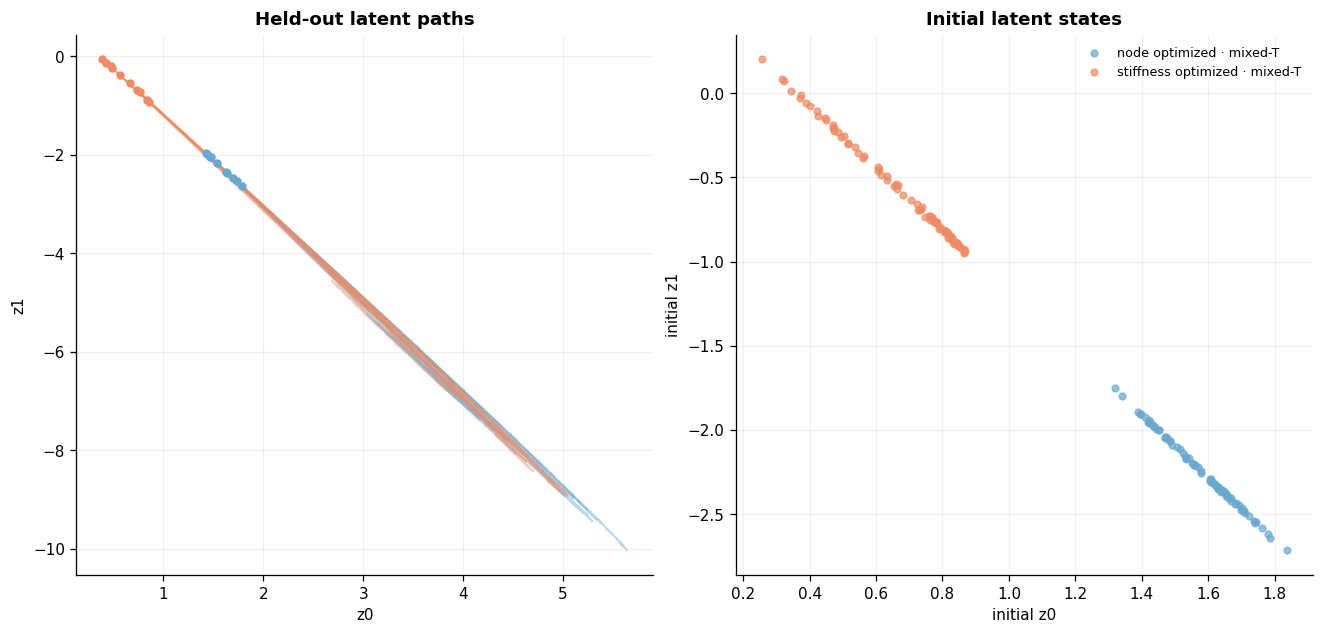

In [5]:
fig, axes = plt.subplots(1, 2, figsize=PAPER_WIDE_FIGSIZE, constrained_layout=True)
for source in MIXED_SOURCES:
    source_values = test_descriptors.query('source == @source').sort_values('final_p_ratio')
    chosen = source_values.iloc[np.linspace(0, len(source_values)-1, 10).round().astype(int)]
    for trajectory_id in chosen.trajectory_id:
        trajectory = frame_df.query('source == @source and trajectory_id == @trajectory_id').sort_values('frame')
        axes[0].plot(trajectory.z0, trajectory.z1, color=SOURCE_COLORS[source], alpha=.45, lw=1.0)
    axes[0].scatter(chosen.z0, chosen.z1, color=SOURCE_COLORS[source], s=18, label=SOURCE_LABELS[source], zorder=3)

for source in MIXED_SOURCES:
    points = test_descriptors.query('source == @source')
    axes[1].scatter(points.z0, points.z1, s=17, color=SOURCE_COLORS[source], alpha=.70, label=SOURCE_LABELS[source])

axes[0].set(title='Held-out latent paths', xlabel='z0', ylabel='z1')
axes[1].set(title='Initial latent states', xlabel='initial z0', ylabel='initial z1')
axes[1].legend(fontsize=8, loc='best')
plt.show()


## Early latent response


Held-out low-T z0 trajectories: this raw coordinate has the stronger initial correlation with final endpoint p-ratio in stiffness-optimized low-T data (r=-0.858). One representative closest to the all-80 regression line is selected from each p-ratio quartile. Colour denotes endpoint p-ratio; line style denotes source. The right column enlarges frames 0–20.


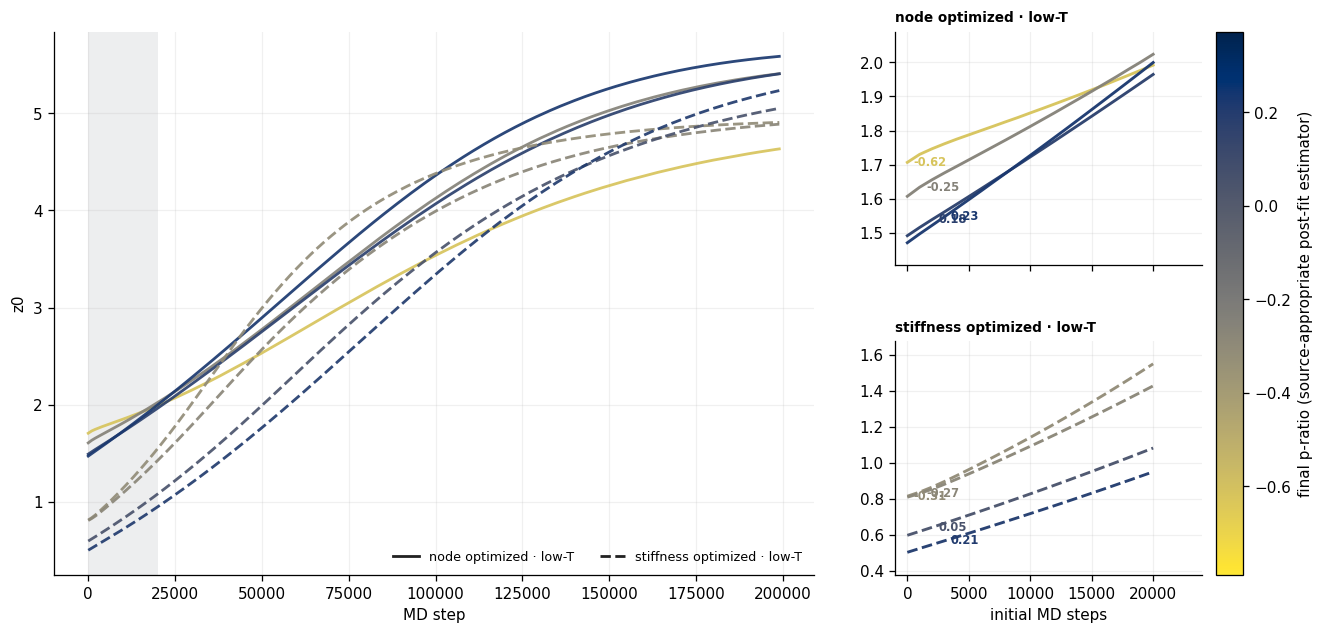

,source,rank,trajectory_id,final_p_ratio,latent_coordinate,initial_latent
0,node optimized · low-T,1,97,-0.619,z0,1.707
1,node optimized · low-T,2,86,-0.251,z0,1.607
2,node optimized · low-T,3,54,0.176,z0,1.492
3,node optimized · low-T,4,58,0.226,z0,1.471
4,stiffness optimized · low-T,1,70,-0.309,z0,0.814
5,stiffness optimized · low-T,2,101,-0.275,z0,0.808
6,stiffness optimized · low-T,3,54,0.049,z0,0.597
7,stiffness optimized · low-T,4,49,0.207,z0,0.502


In [6]:
stiffness_low_values = test_descriptors.query("source == 'stiffness_low'")
stiffness_initial_r = {latent: stiffness_low_values[latent].corr(stiffness_low_values.final_p_ratio) for latent in ['z0','z1']}
TRAJECTORY_LATENT = max(stiffness_initial_r, key=lambda latent: abs(stiffness_initial_r[latent]))
print(f'Held-out low-T {TRAJECTORY_LATENT} trajectories: this raw coordinate has the stronger initial correlation with final endpoint p-ratio in stiffness-optimized low-T data (r={stiffness_initial_r[TRAJECTORY_LATENT]:+.3f}). One representative closest to the all-80 regression line is selected from each p-ratio quartile. Colour denotes endpoint p-ratio; line style denotes source. The right column enlarges frames 0–20.')
line_style_cycle = ['-', '--', ':', '-.']
line_styles = {source: line_style_cycle[index] for index, source in enumerate(LOW_SOURCES)}
plot_values = test_descriptors.query('source in @LOW_SOURCES').final_p_ratio.replace([np.inf, -np.inf], np.nan).dropna()
norm = Normalize(vmin=plot_values.quantile(.01), vmax=plot_values.quantile(.99))
cmap = plt.get_cmap('cividis_r')
INITIAL_ZOOM_FRAME = 20

trajectory_figsize = (PAPER_WIDE_FIGSIZE[0], max(PAPER_WIDE_FIGSIZE[1], 1.75*len(LOW_SOURCES)))
fig = plt.figure(figsize=trajectory_figsize, constrained_layout=True)
grid = fig.add_gridspec(len(LOW_SOURCES), 2, width_ratios=[4.7, 1.9], hspace=.08, wspace=.07)
ax = fig.add_subplot(grid[:, 0])
zoom_axes = [fig.add_subplot(grid[row, 1]) for row in range(len(LOW_SOURCES))]
selected_rows, selected_trajectories = [], []

for source in LOW_SOURCES:
    networks = test_descriptors.query('source == @source').sort_values('final_p_ratio')
    fit = np.polyfit(networks.final_p_ratio, networks[TRAJECTORY_LATENT], 1)
    networks = networks.assign(
        fit_residual=(networks[TRAJECTORY_LATENT]-np.polyval(fit, networks.final_p_ratio)).abs(),
        response_quartile=pd.qcut(networks.final_p_ratio, 4, labels=False),
    )
    selected_indices = [group.fit_residual.idxmin() for _, group in networks.groupby('response_quartile')]
    selected = networks.loc[selected_indices].sort_values('final_p_ratio')
    for rank, (_, network) in enumerate(selected.iterrows(), start=1):
        trajectory_id = int(network.trajectory_id)
        trajectory = frame_df.query('source == @source and trajectory_id == @trajectory_id').sort_values('frame')
        color = cmap(norm(network.final_p_ratio))
        ax.plot(trajectory.frame*1000, trajectory[TRAJECTORY_LATENT], color=color, linestyle=line_styles[source], lw=1.75, alpha=.92)
        entry = {'source': source, 'rank': rank, 'final_p_ratio': float(network.final_p_ratio), 'trajectory': trajectory, 'color': color}
        selected_trajectories.append(entry)
        selected_rows.append({'source': source, 'rank': rank, 'trajectory_id': trajectory_id, 'final_p_ratio': float(network.final_p_ratio), 'latent_coordinate': TRAJECTORY_LATENT, 'initial_latent': float(trajectory[TRAJECTORY_LATENT].iloc[0])})

ax.axvspan(0, INITIAL_ZOOM_FRAME*1000, color='#58606b', alpha=.10, lw=0)
for source in LOW_SOURCES:
    ax.plot([], [], color='#222222', linestyle=line_styles[source], lw=1.75, label=SOURCE_LABELS[source])
ax.set(xlabel='MD step', ylabel=TRAJECTORY_LATENT)
ax.legend(fontsize=8, ncol=2)

for zoom_ax, source in zip(zoom_axes, LOW_SOURCES):
    entries = [entry for entry in selected_trajectories if entry['source'] == source]
    initial_values = []
    for entry in entries:
        initial_part = entry['trajectory'].query('frame <= @INITIAL_ZOOM_FRAME')
        initial_values.extend(initial_part[TRAJECTORY_LATENT].tolist())
        zoom_ax.plot(initial_part.frame*1000, initial_part[TRAJECTORY_LATENT], color=entry['color'], linestyle=line_styles[source], lw=1.8, alpha=.96)
        label_point = initial_part.iloc[min(entry['rank']-1, len(initial_part)-1)]
        zoom_ax.annotate(f"{entry['final_p_ratio']:.2f}", xy=(float(label_point.frame*1000), float(label_point[TRAJECTORY_LATENT])), xytext=(4, 0), textcoords='offset points', ha='left', va='center', fontsize=7.2, color=entry['color'], fontweight='semibold')
    low, high = min(initial_values), max(initial_values)
    pad = .12*max(high-low, 1e-6)
    zoom_ax.set_ylim(low-pad, high+pad)
    zoom_ax.set_xlim(-1000, (INITIAL_ZOOM_FRAME+4)*1000)
    zoom_ax.set_title(SOURCE_LABELS[source], fontsize=8.5, loc='left')
    if zoom_ax is not zoom_axes[-1]:
        zoom_ax.tick_params(axis='x', labelbottom=False)
    else:
        zoom_ax.set_xlabel('initial MD steps')

fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=[ax, *zoom_axes], label='final p-ratio (source-appropriate post-fit estimator)', pad=.012, fraction=.035)
selected_latent_trajectories = pd.DataFrame(selected_rows)
plt.show()
display(selected_latent_trajectories.assign(source=lambda x: x.source.map(SOURCE_LABELS)).round(3))


## Initial latent and p-ratio

Node-optimized and stiffness-optimized mixed-T held-out networks are overlaid on the same axes. The p-ratio is the thermal-noise-reduced strain fit over frames 30–199. Circles and triangles are unseen networks; stars are the actual ID 0 training trajectories. Correlations use held-out networks only.


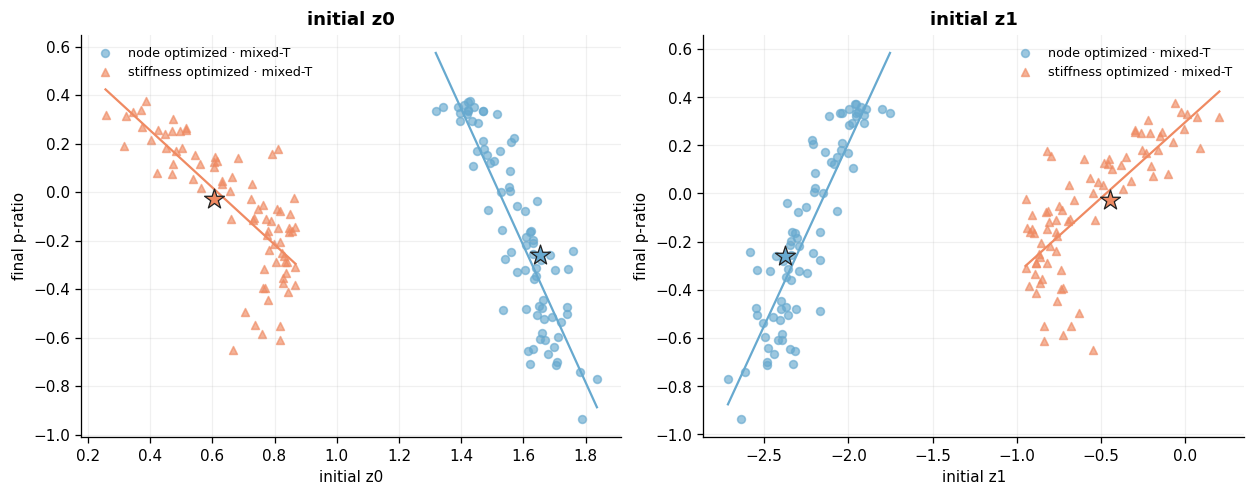

,source,latent,|Pearson r|,|Spearman rho|,valid/total
0,node optimized · mixed-T,initial z0,0.878,0.874,80/80
1,stiffness optimized · mixed-T,initial z0,0.764,0.767,80/80
2,node optimized · mixed-T,initial z1,0.882,0.876,80/80
3,stiffness optimized · mixed-T,initial z1,0.754,0.759,80/80


In [7]:
corr_rows = []
fig,axes=plt.subplots(1,2,figsize=(10.8,4.2),constrained_layout=True)
markers={'node_mixed':'o','stiffness_mixed':'^'}
for ax,latent in zip(axes,['z0','z1']):
    for source in MIXED_SOURCES:
        values=test_descriptors.query('source==@source')
        corr_rows.append({'source':SOURCE_LABELS[source],'latent':f'initial {latent}',
                          '|Pearson r|':abs(values[latent].corr(values.final_p_ratio)),
                          '|Spearman rho|':abs(values[latent].corr(values.final_p_ratio,method='spearman')),
                          'valid/total':f'{len(values)}/{len(values)}'})
        ax.scatter(values[latent],values.final_p_ratio,s=24,alpha=.65,
                   color=SOURCE_COLORS[source],marker=markers[source],label=SOURCE_LABELS[source])
        coef=np.polyfit(values[latent],values.final_p_ratio,1)
        xx=np.linspace(values[latent].min(),values[latent].max(),100)
        ax.plot(xx,np.polyval(coef,xx),color=SOURCE_COLORS[source],lw=1.4)
        trained=training_markers.query('source==@source').iloc[0]
        ax.scatter(trained[f'initial_{latent}'],trained.training_p_ratio,marker='*',s=170,
                   color=SOURCE_COLORS[source],edgecolor='#222222',linewidth=.8,zorder=5)
    ax.set(title=f'initial {latent}',xlabel=f'initial {latent}',ylabel='final p-ratio')
    ax.legend(fontsize=8)
plt.show()
correlations=pd.DataFrame(corr_rows)
display(correlations.round({'|Pearson r|':3,'|Spearman rho|':3}))


## Temperature and fluctuation

For each held-out mixed-T trajectory, fluctuation is the standard deviation of transverse-displacement residuals after removing the fitted response to axial displacement over frames 30–199. The model's only mixed-T training trajectory was at 0.1 K; held-out trajectories span 0.1–30 K.


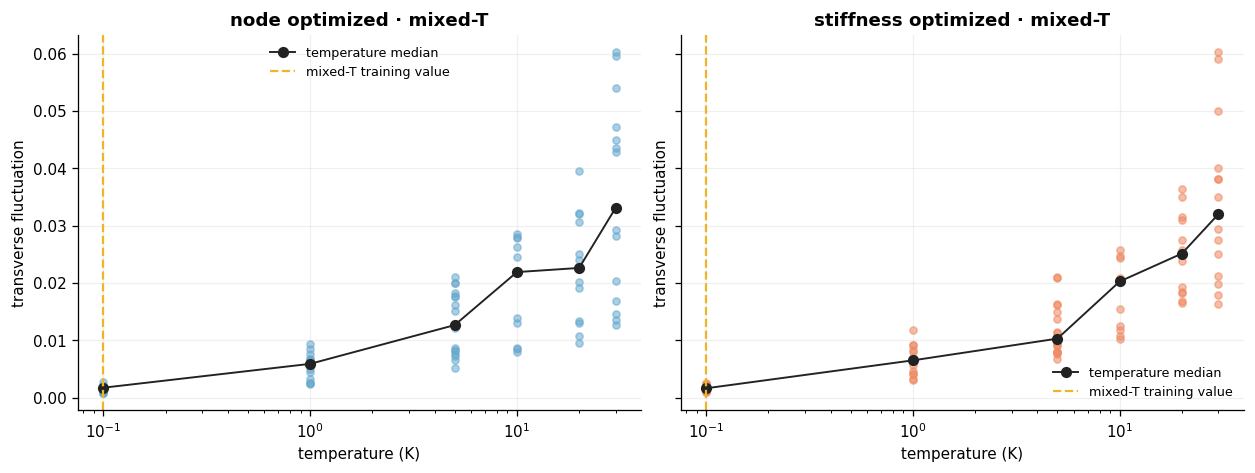

,source,Pearson r vs log10(T),Spearman rho vs T,valid,total,training_mixed_temperature_K,heldout_temperature_min_K,heldout_temperature_max_K
0,node_mixed,0.700,0.841,80,80,0.1,0.1,30.0
1,stiffness_mixed,0.754,0.901,80,80,0.1,0.1,30.0


The positive correlations show that the held-out data contain a real temperature-dependent fluctuation signal. Evaluation up to 30 K is therefore outside the single 0.1 K mixed-T training example. This supports temperature generalization, but the association alone is not proof of causal temperature extrapolation because network identity also varies across held-out trajectories.


In [8]:
fig,axes=plt.subplots(1,2,figsize=(10.8,4.0),sharey=True,constrained_layout=True)
for ax,source in zip(axes,['node_mixed','stiffness_mixed']):
    values=temperature_fluctuation.query('source==@source')
    summary=temperature_fluctuation_summary.query('source==@source').iloc[0]
    ax.scatter(values.temperature_K,values.transverse_fluctuation_sd,s=20,alpha=.55,color=SOURCE_COLORS[source])
    medians=values.groupby('temperature_K',as_index=False).transverse_fluctuation_sd.median()
    ax.plot(medians.temperature_K,medians.transverse_fluctuation_sd,'o-',color='#222222',lw=1.2,label='temperature median')
    ax.axvline(.1,color='#f0b429',linestyle='--',lw=1.4,label='mixed-T training value')
    ax.set_xscale('log')
    ax.set(title=SOURCE_LABELS[source],xlabel='temperature (K)',ylabel='transverse fluctuation')
    ax.legend(fontsize=8)
plt.show()
display(temperature_fluctuation_summary.rename(columns={'pearson_fluctuation_vs_log10_temperature':'Pearson r vs log10(T)','spearman_fluctuation_vs_temperature':'Spearman rho vs T'}).round(3))
print('The positive correlations show that the held-out data contain a real temperature-dependent fluctuation signal. Evaluation up to 30 K is therefore outside the single 0.1 K mixed-T training example. This supports temperature generalization, but the association alone is not proof of causal temperature extrapolation because network identity also varies across held-out trajectories.')


## Latent coordinates through time

Raw coordinates for five held-out systems per low-T family over frames 0–99; no centering, rotation, smoothing, or rescaling.

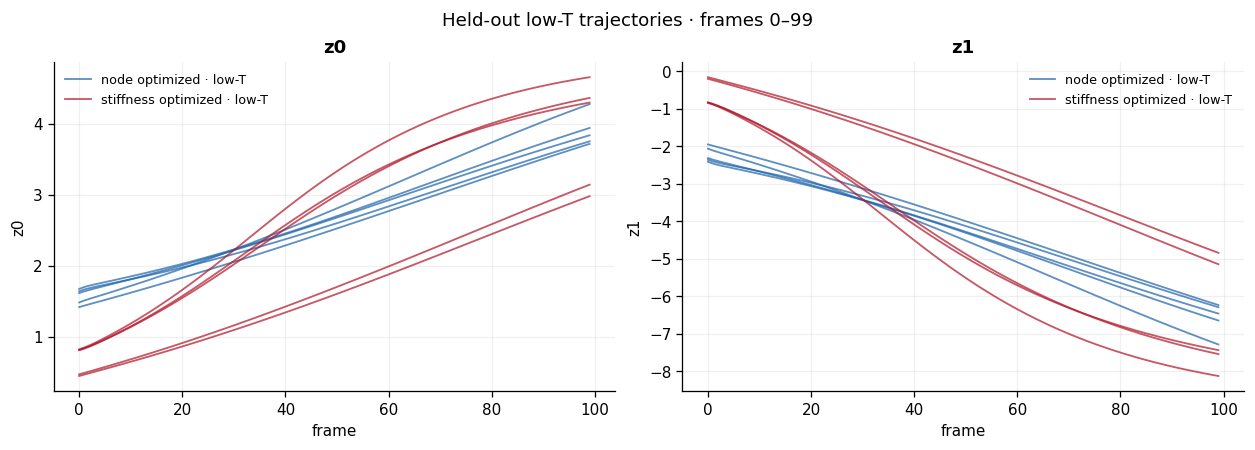

In [9]:
import sys
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from lss.plotting import plot_latent_coordinates
rng=np.random.default_rng(17)
selected={source:sorted(rng.choice(frame_df.query('source==@source').trajectory_id.unique(),5,replace=False)) for source in LOW_SOURCES}
fig, axes = plot_latent_coordinates(
    frame_df, selected, SOURCE_LABELS, SOURCE_COLORS,
    frame_stop=100, title='Held-out low-T trajectories · frames 0–99',
)
plt.show()


## Same latent, opposite box response

Held-out low-T node network 47 and stiffness network 106 nearly meet in both latent coordinates at frame 33. The physical curve uses the **raw box height change from frame 0**, not the boundary-node estimator used for notebook p-ratio. The exact frame-33 values are below the plot.


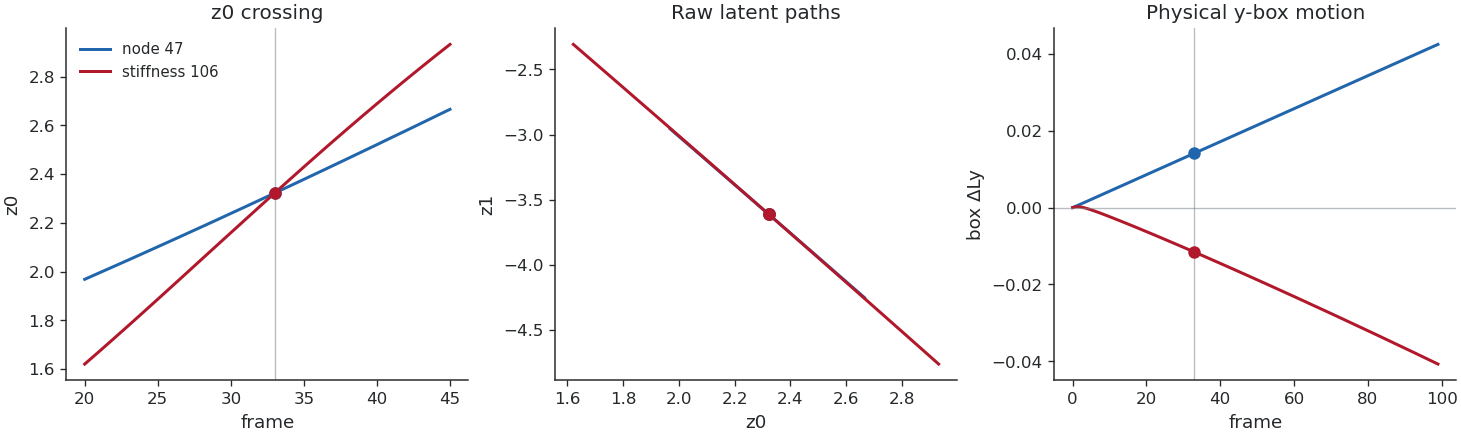

Frame 33 · 2D latent separation 0.000173 · both box x-strains -0.00330


,network,z0,z1,box ΔLy,box y-strain,box p-ratio
0,node 47,2.322643,-3.612332,0.014122,0.001108,0.335668
1,stiffness 106,2.322780,-3.612437,-0.011566,-0.000814,-0.246577


In [10]:
import sys
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from lss.plotting import apply_editorial_style, style_axes
apply_editorial_style('light')

pair_box = pd.read_csv(PROJECT_ROOT / 'notebooks/results/all4_coverage_1000/notebook01_crossing_pair/raw_box_motion.csv')
PAIR_IDS = {'node_low': 47, 'stiffness_low': 106}
PAIR_FRAME = 33
assert len(pair_box) == 400

fig, axes = plt.subplots(1, 3, figsize=(12.2, 3.65), constrained_layout=True)
for source in LOW_SOURCES:
    trajectory_id = PAIR_IDS[source]
    color = SOURCE_COLORS[source]
    name = 'node 47' if source == 'node_low' else 'stiffness 106'
    latent = frame_df.query('source == @source and trajectory_id == @trajectory_id and frame <= 99').sort_values('frame')
    box = pair_box.query('source == @source and trajectory_id == @trajectory_id and frame <= 99').sort_values('frame')
    assert latent.frame.tolist() == box.frame.tolist() == list(range(100))
    near = latent.query('20 <= frame <= 45')
    point = latent.query('frame == @PAIR_FRAME').iloc[0]
    box_point = box.query('frame == @PAIR_FRAME').iloc[0]
    axes[0].plot(near.frame, near.z0, color=color, label=name, lw=1.8)
    axes[0].scatter(PAIR_FRAME, point.z0, color=color, s=42, zorder=3)
    axes[1].plot(near.z0, near.z1, color=color, lw=1.8)
    axes[1].scatter(point.z0, point.z1, color=color, s=45, zorder=3)
    axes[2].plot(box.frame, box.delta_Ly, color=color, lw=1.8)
    axes[2].scatter(PAIR_FRAME, box_point.delta_Ly, color=color, s=42, zorder=3)

axes[0].set_title('z0 crossing')
axes[1].set_title('Raw latent paths')
axes[2].set_title('Physical y-box motion')
axes[0].axvline(PAIR_FRAME, color='#7a858c', lw=.8, alpha=.55)
axes[2].axvline(PAIR_FRAME, color='#7a858c', lw=.8, alpha=.55)
axes[2].axhline(0, color='#7a858c', lw=.8, alpha=.55)
style_axes(axes[0], xlabel='frame', ylabel='z0', legend=True)
style_axes(axes[1], xlabel='z0', ylabel='z1')
style_axes(axes[2], xlabel='frame', ylabel='box ΔLy')
plt.show()

latent_at_33 = frame_df.query('frame == @PAIR_FRAME and ((source == "node_low" and trajectory_id == 47) or (source == "stiffness_low" and trajectory_id == 106))')
box_at_33 = pair_box.query('frame == @PAIR_FRAME')
values = latent_at_33.merge(box_at_33, on=['source', 'trajectory_id', 'frame'], validate='one_to_one')
assert len(values) == 2
assert values.set_index('source').loc['node_low', 'delta_Ly'] > 0 > values.set_index('source').loc['stiffness_low', 'delta_Ly']
latent_distance = np.linalg.norm(values[['z0', 'z1']].to_numpy()[0] - values[['z0', 'z1']].to_numpy()[1])
print(f'Frame 33 · 2D latent separation {latent_distance:.6f} · both box x-strains {values.strain_x.iloc[0]:.5f}')
display(values.assign(network=values.source.map({'node_low': 'node 47', 'stiffness_low': 'stiffness 106'}))
        [['network', 'z0', 'z1', 'delta_Ly', 'strain_y', 'box_p_ratio']]
        .rename(columns={'delta_Ly': 'box ΔLy', 'strain_y': 'box y-strain', 'box_p_ratio': 'box p-ratio'})
        .round(6).reset_index(drop=True))


## Scope

The one-each model is a deliberately severe data limit: four trajectories, only two unique structures, and one mixed temperature (0.1 K) per branch. Its result is the held-out ordering from initial latent state to final p-ratio, with the actual negative-response training point shown explicitly. The experiment cannot establish broad mixed-temperature coverage. Notebook 02 uses the matched 20-per-source model to test whether additional structure and temperature coverage make the latent organization richer.
